# UCI Heart Failure Dataset — Exploratory Data Analysis

This notebook explores the UCI Heart Failure Clinical Records dataset.
299 patients, 13 clinical features, binary death event target.
Goal: understand feature distributions, class balance, and clinical 
correlations before modeling.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully")

Libraries loaded successfully


In [4]:
heart_failure = fetch_ucirepo(id=519)

X = heart_failure.data.features
y = heart_failure.data.targets

df = pd.concat([X, y], axis=1)

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
df.head()

Dataset shape: (299, 13)

Columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'death_event']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## Basic data quality check
Before doing any analysis we need to confirm the data is clean — 
no missing values, correct data types, and sensible ranges.

In [7]:
print("=== Data Types ===")
print(df.dtypes)
print(f"\n=== Missing Values ===")
print(df.isnull().sum())
print(f"\n=== Basic Statistics ===")
df.describe().round(2)

=== Data Types ===
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
death_event                   int64
dtype: object

=== Missing Values ===
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
death_event                 0
dtype: int64

=== Basic Statistics ===


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26,0.32
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61,0.47
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00,0.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00,0.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00,0.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00,1.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00,1.00


## Class distribution
How many patients survived vs died? Class imbalance affects 
model training — if most patients survived, a lazy model could 
just predict "survived" every time and still look accurate.

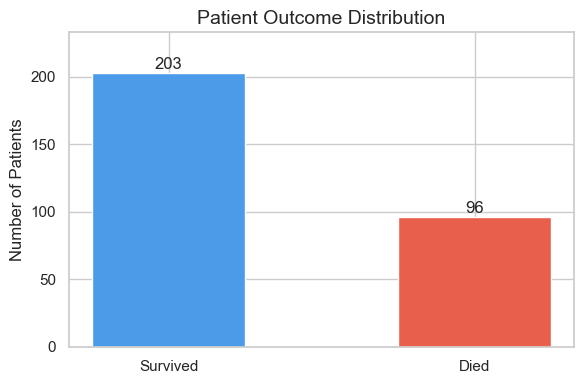

Class balance: 203 survived (67.9%), 96 died (32.1%)


In [8]:
fig, ax = plt.subplots(figsize=(6, 4))

counts = df['death_event'].value_counts()
labels = ['Survived', 'Died']
colors = ['#4C9BE8', '#E8604C']

bars = ax.bar(labels, counts.values, color=colors, width=0.5)

for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 3,
            str(count), ha='center', fontsize=12)

ax.set_title('Patient Outcome Distribution', fontsize=14)
ax.set_ylabel('Number of Patients')
ax.set_ylim(0, counts.max() + 30)

plt.tight_layout()
plt.savefig('../reports/figures/01_class_distribution.png', dpi=150)
plt.show()

print(f"Class balance: {counts[0]} survived ({counts[0]/len(df)*100:.1f}%), "
      f"{counts[1]} died ({counts[1]/len(df)*100:.1f}%)")

## Feature distributions
How are the clinical measurements spread across the dataset? 
Looking at the shape of each feature helps spot skewed data, 
outliers, and unusual patterns before modeling.

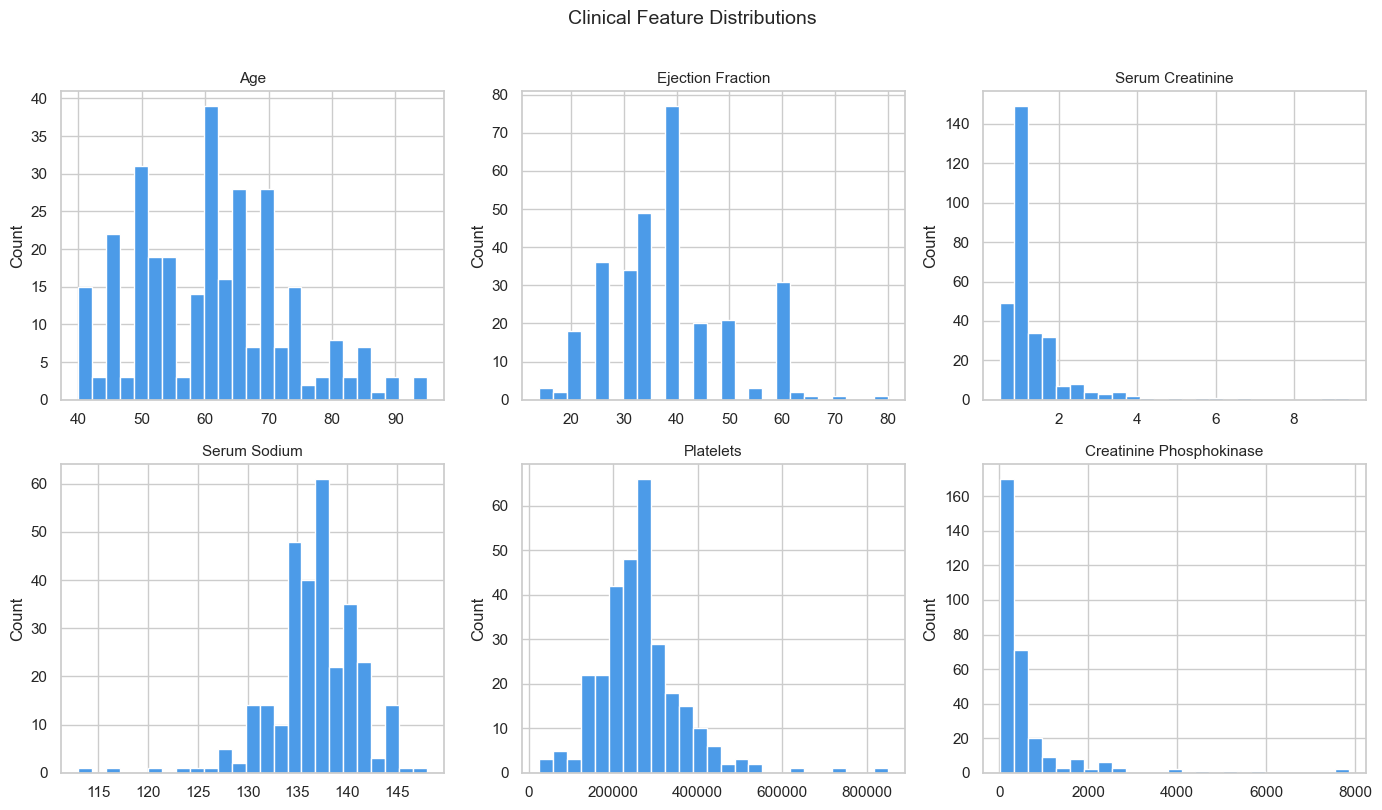

In [9]:
numeric_cols = ['age', 'ejection_fraction', 'serum_creatinine',
                'serum_sodium', 'platelets', 'creatinine_phosphokinase']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=25, color='#4C9BE8', edgecolor='white')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=11)
    axes[i].set_ylabel('Count')

plt.suptitle('Clinical Feature Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/01_feature_distributions.png', dpi=150)
plt.show()

## Ejection fraction vs survival
Ejection fraction measures how much blood the heart pumps per beat.
Lower values indicate more severe heart failure — does it separate 
survivors from non-survivors?

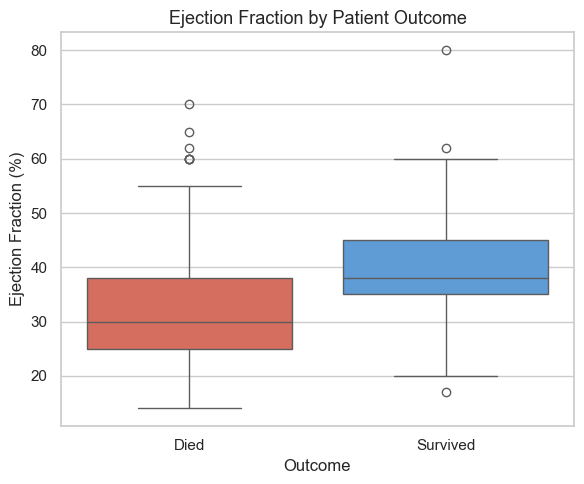

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))

df_plot = df.copy()
df_plot['Outcome'] = df_plot['death_event'].map({0: 'Survived', 1: 'Died'})

sns.boxplot(data=df_plot, x='Outcome', y='ejection_fraction',
            hue='Outcome',
            palette={'Survived': '#4C9BE8', 'Died': '#E8604C'},
            legend=False, ax=ax)

ax.set_title('Ejection Fraction by Patient Outcome', fontsize=13)
ax.set_xlabel('Outcome')
ax.set_ylabel('Ejection Fraction (%)')

plt.tight_layout()
plt.savefig('../reports/figures/01_ejection_fraction_outcome.png', dpi=150)
plt.show()

## Feature correlation matrix
Which features are most correlated with each other and 
with survival? Strong correlations reveal which clinical 
measurements move together and which are the strongest 
predictors of outcome.

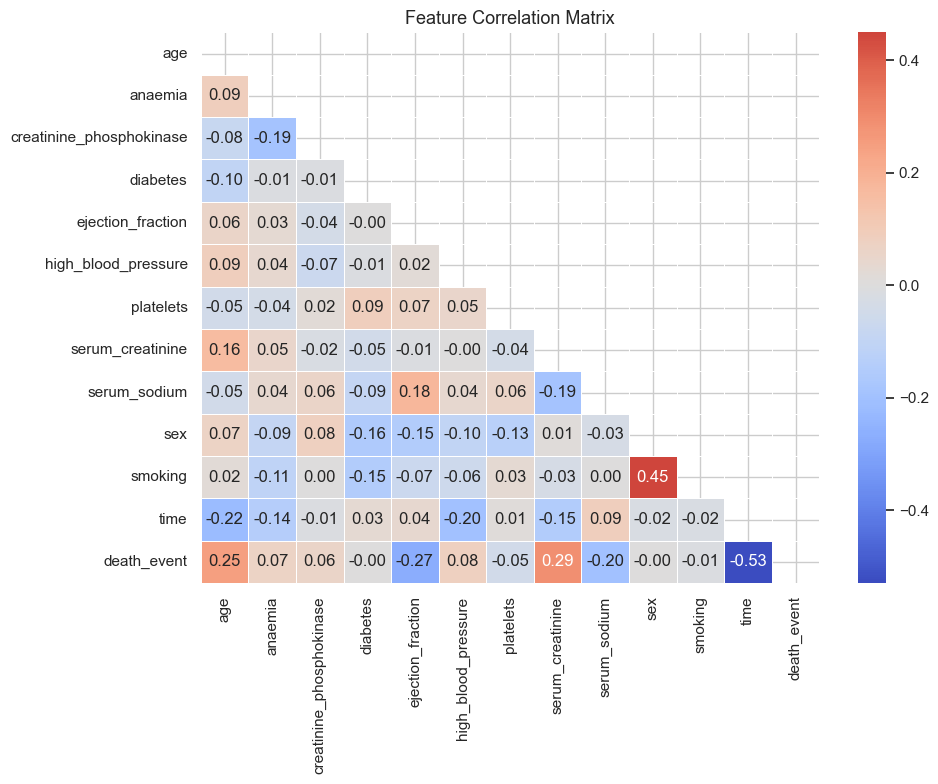

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))

corr = df.corr().round(2)
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            linewidths=0.5, ax=ax)

ax.set_title('Feature Correlation Matrix', fontsize=13)
plt.tight_layout()
plt.savefig('../reports/figures/01_correlation_matrix.png', dpi=150)
plt.show()

## Key findings

- Dataset has 299 patients: 203 survived (67.9%), 96 died (32.1%) — 
  moderate class imbalance, models will need to account for this
- Ejection fraction is notably lower in patients who died — 
  a clinically meaningful signal confirmed visually
- Serum creatinine shows the second strongest positive correlation 
  with death event — kidney function is a key comorbidity
- Time (follow-up period) is the strongest single predictor at -0.53 — 
  patients who died did so early in the observation window
- No missing values — dataset is clean and ready for feature engineering
- Serum creatinine and creatinine phosphokinase show heavy right skew — 
  will need log transformation before modeling